<a href="https://colab.research.google.com/github/rudacad18/montecarlosim/blob/main/monte_carlo_simulation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import math
import numpy as np
import matplotlib.pyplot as plt
from pandas_datareader import data # we can get data sheets from here

Yahoo shut down the old public API it relied on, and the library dropped it, so DataReader('AAPL', 'yahoo', ...) will always raise NotImplementedError.

In [ ]:
import yfinance as yf

apple = yf.download('AAPL', start='2000-01-01')

/tmp/ipykernel_855/735649032.py:3: FutureWarning: YF.download() has changed argument auto_adjust default to True
  apple = yf.download('AAPL', start='2000-01-01')
[*********************100%***********************]  1 of 1 completed


In [ ]:
apple.head()

Price,Close,High,Low,Open,Volume
Ticker,AAPL,AAPL,AAPL,AAPL,AAPL
Date,,,,,
2000-01-03,0.837002,0.841208,0.760359,0.784193,535796800
2000-01-04,0.766435,0.827188,0.756621,0.809430,512377600
2000-01-05,0.777650,0.826721,0.770173,0.775781,778321600
2000-01-06,0.710353,0.800082,0.710353,0.793540,767972800
2000-01-07,0.744002,0.755218,0.714093,0.721570,460734400


In [ ]:
time_elapsed = (apple.index[-1]- apple.index[0]).days #number of days that have elapsed for every price point

Then, we compute the compounded annual growth rate (cagr) by taking the ratio between the closing price and the opening price and rasing that value to the inverse of the number of years elapsed then substract 1 (in order to make it a percentage of growth).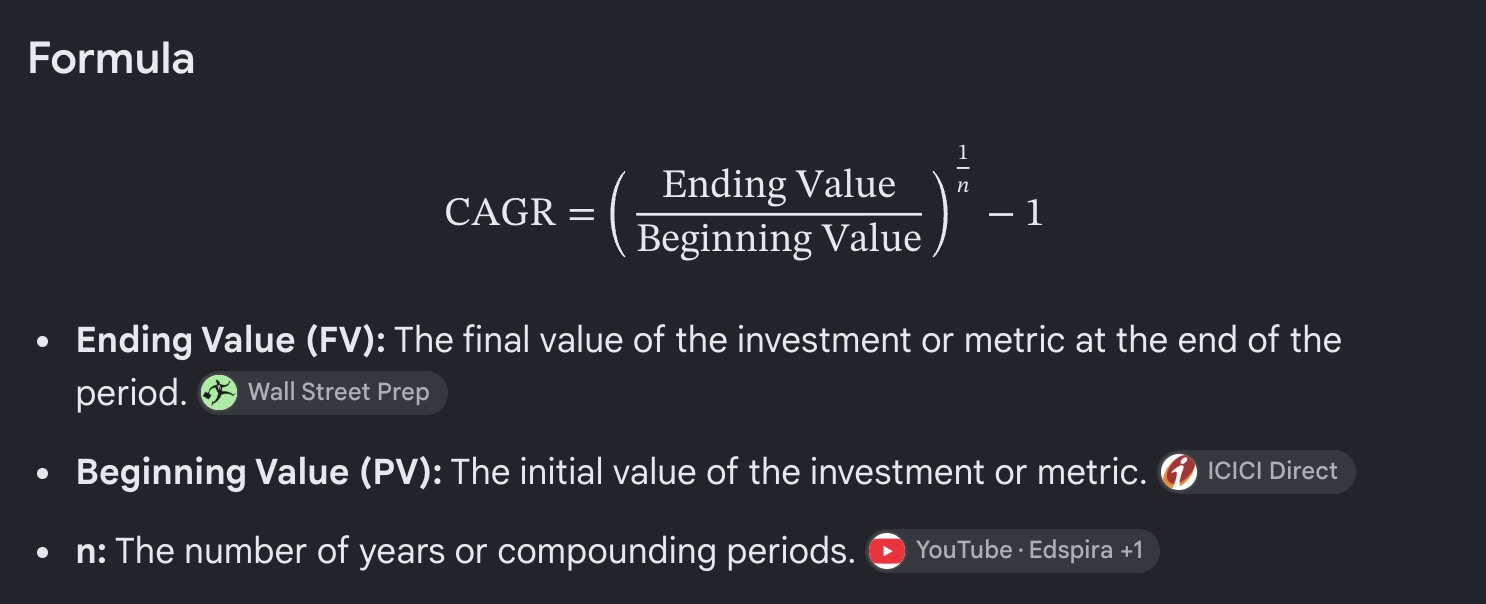

In [ ]:
price_ratio = (apple['Close'].iloc[-1]/apple['Close'].iloc[1])
inverse_number_of_years = 365.0/time_elapsed
cagr = price_ratio**inverse_number_of_years - 1

Now, let's determine the annual volatility of returns. Volatility is the standard deviation of the percent changes in price for each day. This makes sense since it is a measure of how sporadically the price of the stock is changing.

In [ ]:
vol = apple['Close'].pct_change().std()

Now, in order to make this figure useful as an annual measure, it has to be scaled by an annualization factor. This factor is most often the square root of the number of trading days in a year which happens to be 252.

In [ ]:
number_of_trading_days = 252
vol = vol * math.sqrt(number_of_trading_days)

Let's see what we get.

In [ ]:
print ("cagr (mean returns) : ", str(round(cagr,4)))
print ("vol (standard deviation of return : )", str(round(vol,4)))

cagr (mean returns) :  Ticker
AAPL    0.255
dtype: float64
vol (standard deviation of return : ) Ticker
AAPL    0.3819
dtype: float64


##2. Generate Random Values
For this, we'll use the normal function from the numpy library.

In [ ]:
daily_return_percentages = np.random.normal(cagr/number_of_trading_days, vol/math.sqrt(number_of_trading_days), number_of_trading_days) + 1

Let's create a price series from this list. We'll start with the most recent price and go from there. Then, in order to generate each consecutive price, we will apply the price change to the most recent price. This will result in a distribution called a "random walk".

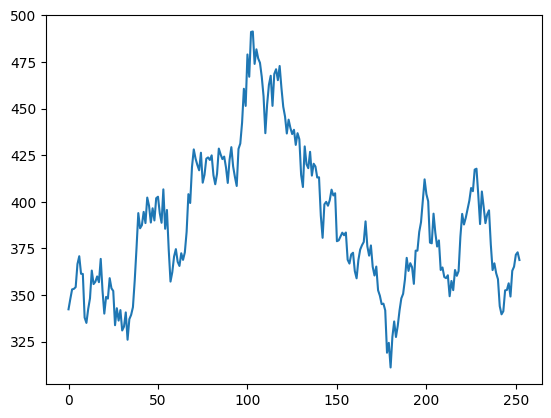

In [ ]:
price_series = [apple['Close'].iloc[-1]]

for drp in daily_return_percentages:
  price_series.append(price_series[-1] * drp)

plt.plot(price_series)
plt.show()

However, this by itself isn't particularly useful since this is just one out of the virtually infinite possible price series for this stock. The actual probability that the stock would follow this price series in the future is unfathomably close to zero.

##3. Apple them over many, many trials

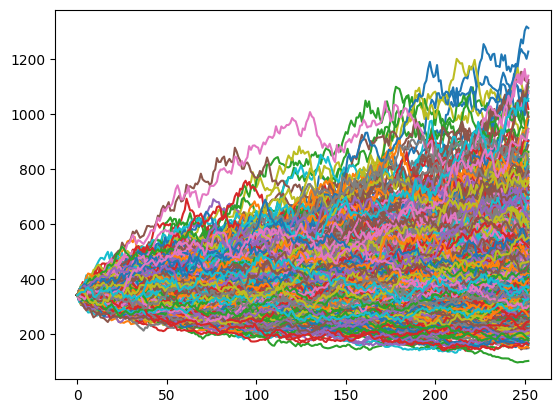

In [ ]:
number_of_trials = 1000

for i in range(number_of_trials):
  daily_return_percentages = np.random.normal(cagr/number_of_trading_days, vol/math.sqrt(number_of_trading_days), number_of_trading_days)+ 1
  price_series = [apple['Close'].iloc[-1]]

  for drp in daily_return_percentages:
    price_series.append(price_series[-1] * drp)

  plt.plot(price_series)

plt.show()

While this chart is really pretty, it can be a bit cumbersome to meake meaninful interpretations from it. Instead, we shall construct a histogram of the ending price points. This way, we can see a distribution of where our "random" predictions "end up".

(array([[1., 0., 0., 0., 0.],
        [0., 1., 0., 0., 0.],
        [0., 1., 0., 0., 0.],
        ...,
        [1., 0., 0., 0., 0.],
        [0., 0., 1., 0., 0.],
        [0., 1., 0., 0., 0.]], shape=(1001, 5)),
 array([  97.30397866,  335.42280115,  573.54162365,  811.66044614,
        1049.77926864, 1287.89809113]),
 <a list of 1001 BarContainer objects>)

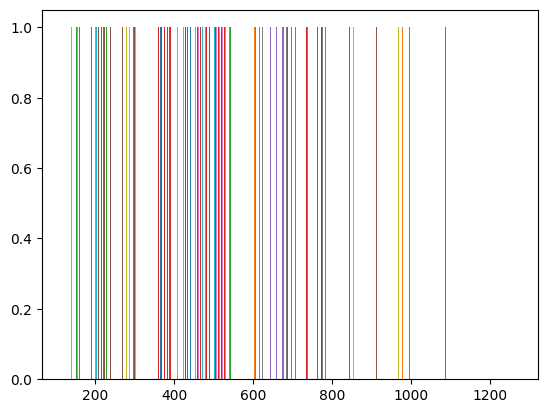

In [ ]:
ending_price_points = []
larger_number_of_trials = 1001 # It's over 9000
for i in range(larger_number_of_trials):
    daily_return_percentages = np.random.normal(cagr/number_of_trading_days, vol/math.sqrt(number_of_trading_days),number_of_trading_days)+1
    price_series = [apple['Close'].iloc[-1]]

    for drp in daily_return_percentages:
        price_series.append(price_series[-1] * drp)

    plt.plot(price_series)

    ending_price_points.append(price_series[-1])

plt.show()

plt.hist(ending_price_points,bins=5)
plt.show()

##4. Collect Results and Analyse

Now, let's get the mean of this distribution in order to get an expected value of our ending price points.

In [ ]:
expected_ending_price_point = round(np.mean(ending_price_points), 2)
print("Expected EndingPrice Point : ", str(expected_ending_price_point))

Expected EndingPrice Point :  446.39


Due to the Law of Large Numbers, this number (which you can think of as the sample mean) will eventually converge to the last, known price point multiplied by the expected daily price change (the population mean).

In [ ]:
population_mean = (cagr+1) * apple['Close'].iloc[-1]
print("Sample Mean: ", str(expected_ending_price_point))
print("Population Mean: ", str(round(population_mean, 2)))
print("Percent Difference: ", str(round((population_mean- expected_ending_price_point)/population_mean*100,2)), "%")

Sample Mean:  446.39
Population Mean:  Ticker
AAPL    429.69
dtype: float64
Percent Difference:  Ticker
AAPL   -3.89
dtype: float64 %


The true usefulness of Monte Carlo simulations, though, is to see the distribution of ending price points and guage risk vs. reward. Let's take the top 10 and bottom 10 percentiles.

In [ ]:
top_ten = np.percentile(ending_price_points,100-10)
bottom_ten = np.percentile(ending_price_points,10);
print ("Top 10% : ", str(round(top_ten,2)))
print ("Bottom 10% : ", str(round(bottom_ten,2)))

Top 10% :  682.55
Bottom 10% :  248.06


In [ ]:
plt.hist(ending_price_points,bins=100)
plt.axvline(top_ten,color='r',linestyle='dashed',linewidth=2)
plt.axvline(bottom_ten,color='r',linestyle='dashed',linewidth=2)
plt.axhline(apple['Close'].iloc[-1],color='g', linestyle='dashed',linewidth=2)
plt.show()

ValueError: The truth value of a Series is ambiguous. Use a.empty, a.bool(), a.item(), a.any() or a.all().

Error in callback <function flush_figures at 0x7d7c3043d1c0> (for post_execute):


KeyboardInterrupt: 